# 03 — Exploratory Data Analysis & Visualizations
### E-Commerce Customer Analytics Dashboard

Covers: revenue analysis, product analysis, profitability analysis, customer
distribution, payment method analysis, and the core visualization set used in
the portfolio README and Power BI design reference.

All charts are saved to `../images/` as PNG files (used in the README and as
a fallback if a viewer can't render Power BI `.pbix` files).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

IMG_DIR = '../images'

df = pd.read_csv('../data/ecommerce_features.csv', parse_dates=['Order_Date'])
print(df.shape)
df.head(3)


(12118, 31)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Year_Quarter,Year_Month,Day_of_Week,Profit_Margin,Gross_Sales,Discount_Amount,Total_Orders,Customer_Lifetime_Value,Average_Order_Value,Is_Repeat_Customer
0,ORD010477,2024-09-08,CUST01027,Aarav Bava,Female,34,Nagpur,Maharashtra,West,Beauty & Personal Care,...,2024-Q3,2024-09,Sunday,47.37,1366.44,68.32,4,11014.37,2753.59,True
1,ORD008646,2023-10-05,CUST00581,Bhavya Borah,Male,37,Ranchi,Jharkhand,East,Sports & Fitness,...,2023-Q4,2023-10,Thursday,40.00,10380.80,0.00,20,159881.56,7994.08,True
2,ORD011576,2023-08-08,CUST00653,Sanya Wable,Female,31,Bhubaneswar,Odisha,East,Books,...,2023-Q3,2023-08,Tuesday,40.00,722.57,0.00,48,358731.11,7473.56,True


## 1. High-Level KPIs

In [2]:
total_revenue = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_customers = df['Customer_ID'].nunique()
avg_order_value = total_revenue / total_orders
profit_margin_pct = (total_profit / total_revenue) * 100

print(f"Total Revenue:        ₹{total_revenue:,.2f}")
print(f"Total Profit:         ₹{total_profit:,.2f}")
print(f"Overall Profit Margin:{profit_margin_pct:6.2f}%")
print(f"Total Orders:         {total_orders:,}")
print(f"Total Customers:      {total_customers:,}")
print(f"Average Order Value:  ₹{avg_order_value:,.2f}")


Total Revenue:        ₹146,834,107.68
Total Profit:         ₹30,863,842.06
Overall Profit Margin: 21.02%
Total Orders:         11,978
Total Customers:      1,137
Average Order Value:  ₹12,258.65


## 2. Monthly Sales Trend

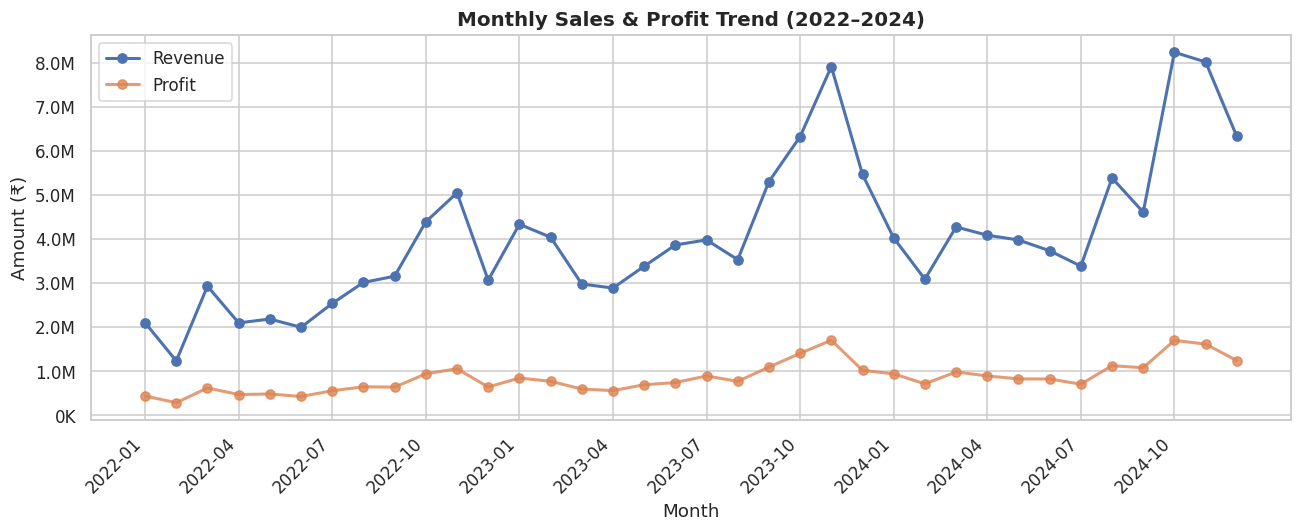

In [3]:
monthly = df.groupby('Year_Month').agg(Revenue=('Sales', 'sum'),
                                        Profit=('Profit', 'sum')).reset_index()
monthly = monthly.sort_values('Year_Month')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly['Year_Month'], monthly['Revenue'], marker='o', linewidth=2, label='Revenue')
ax.plot(monthly['Year_Month'], monthly['Profit'], marker='o', linewidth=2, label='Profit', alpha=0.8)
ax.set_title('Monthly Sales & Profit Trend (2022–2024)')
ax.set_xlabel('Month')
ax.set_ylabel('Amount (₹)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly['Year_Month'].iloc[::3], rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/01_monthly_sales_trend.png', bbox_inches='tight')
plt.show()


## 3. Revenue by Region

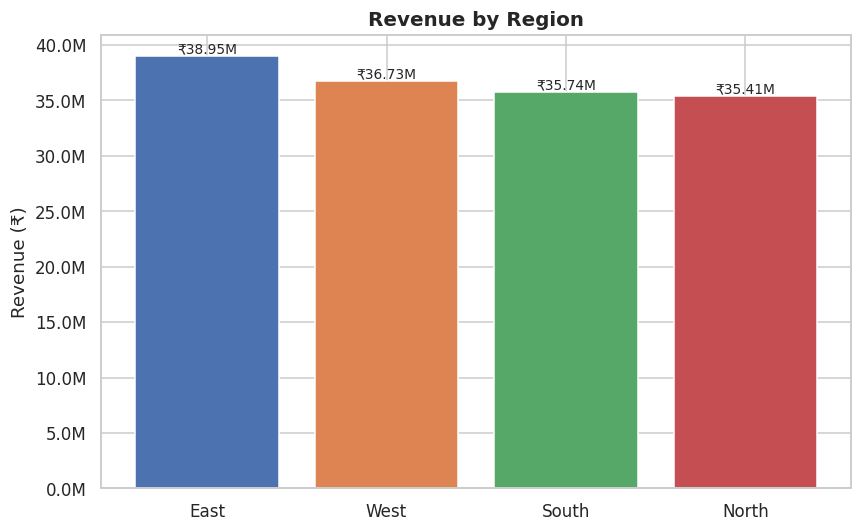

In [4]:
region_rev = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(region_rev.index, region_rev.values, color=sns.color_palette('deep', len(region_rev)))
ax.set_title('Revenue by Region')
ax.set_ylabel('Revenue (₹)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
for bar in bars:
    h = bar.get_height()
    ax.annotate(f'₹{h/1e6:.2f}M', (bar.get_x() + bar.get_width()/2, h),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/02_revenue_by_region.png', bbox_inches='tight')
plt.show()


## 4. Profit by Category

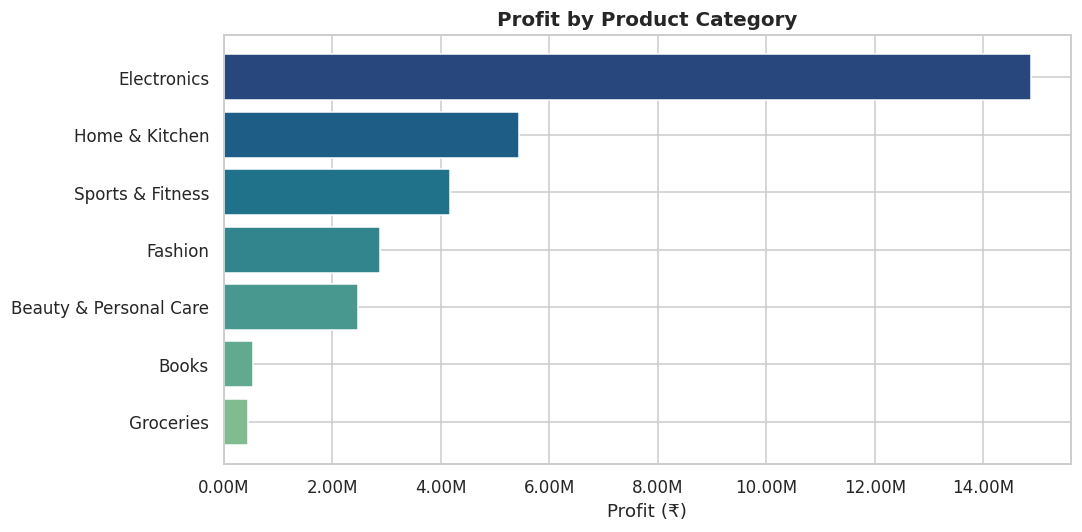

,Revenue,Profit,Margin_Pct
Product_Category,,,
Electronics,99573984.62,14879796.47,14.94
Home & Kitchen,18629902.25,5449293.00,29.25
Sports & Fitness,12208939.64,4181887.44,34.25
Fashion,7243131.45,2880277.34,39.77
Beauty & Personal Care,5508421.21,2478826.41,45.00
Books,1586011.23,549319.74,34.64
Groceries,2083717.28,444441.66,21.33


In [5]:
cat_profit = df.groupby('Product_Category').agg(
    Revenue=('Sales', 'sum'), Profit=('Profit', 'sum')
).sort_values('Profit', ascending=False)
cat_profit['Margin_Pct'] = (cat_profit['Profit'] / cat_profit['Revenue'] * 100).round(2)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(cat_profit.index[::-1], cat_profit['Profit'][::-1], color=sns.color_palette('crest', len(cat_profit)))
ax.set_title('Profit by Product Category')
ax.set_xlabel('Profit (₹)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.2f}M'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/03_profit_by_category.png', bbox_inches='tight')
plt.show()

cat_profit


## 5. Top 10 Products (by Revenue)

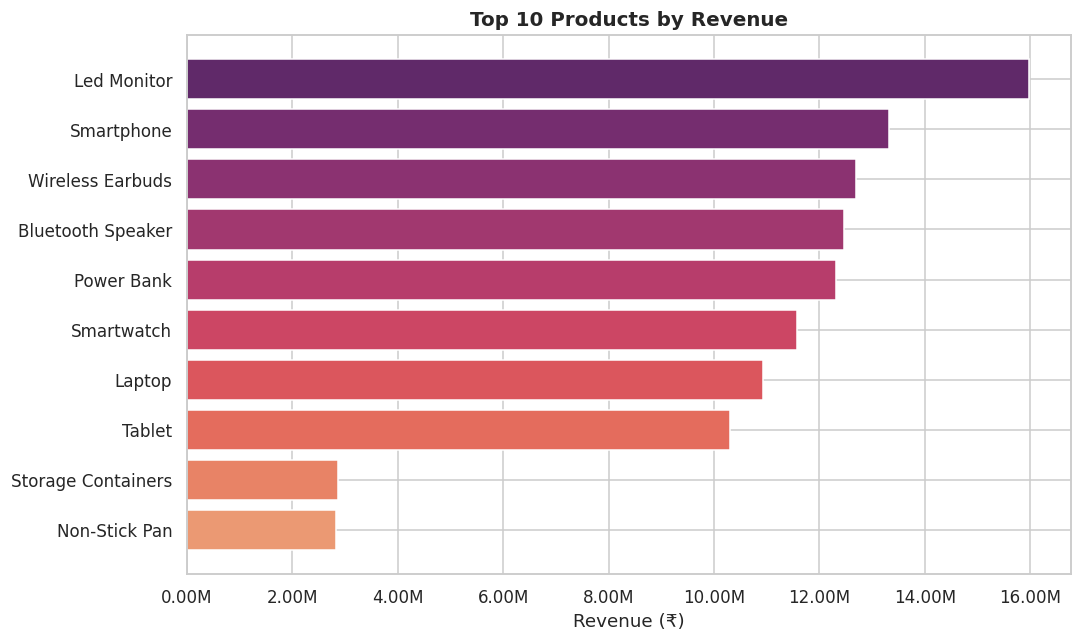

In [6]:
top_products = df.groupby('Product_Name')['Sales'].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_products.index[::-1], top_products.values[::-1], color=sns.color_palette('flare', 10))
ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue (₹)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.2f}M'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/04_top_10_products.png', bbox_inches='tight')
plt.show()


## 6. Customer Distribution (Age & Gender)

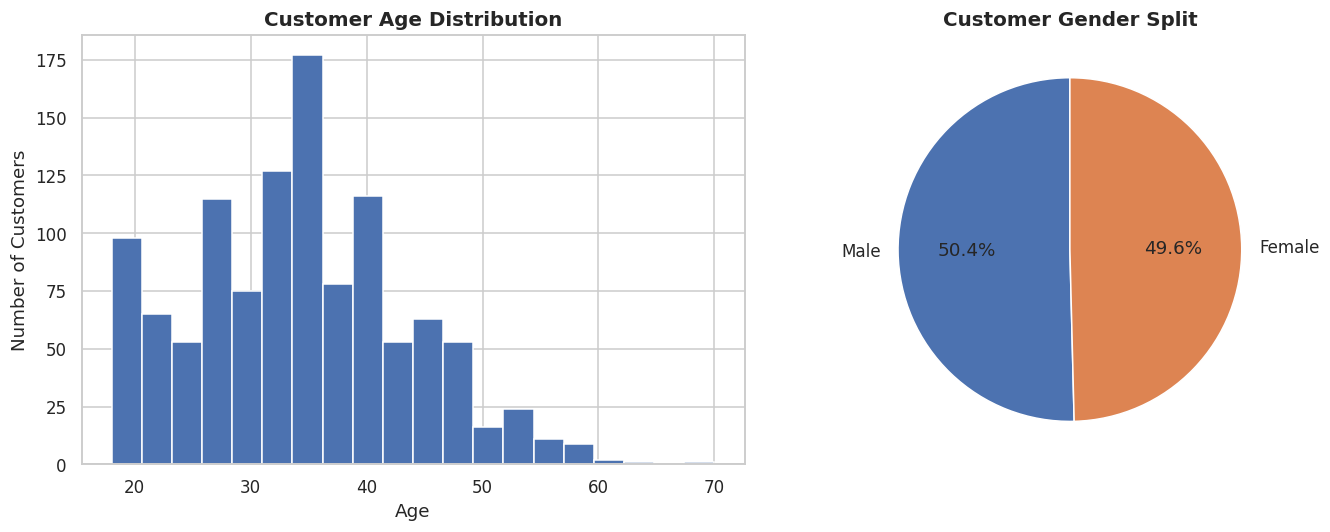

In [7]:
customers = pd.read_csv('../data/customer_features.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(customers['Age'], bins=20, color=sns.color_palette('deep')[0], edgecolor='white')
axes[0].set_title('Customer Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of Customers')

gender_counts = customers['Gender'].value_counts()
axes[1].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('deep', len(gender_counts)), startangle=90)
axes[1].set_title('Customer Gender Split')

plt.tight_layout()
plt.savefig(f'{IMG_DIR}/05_customer_distribution.png', bbox_inches='tight')
plt.show()


## 7. Payment Method Analysis

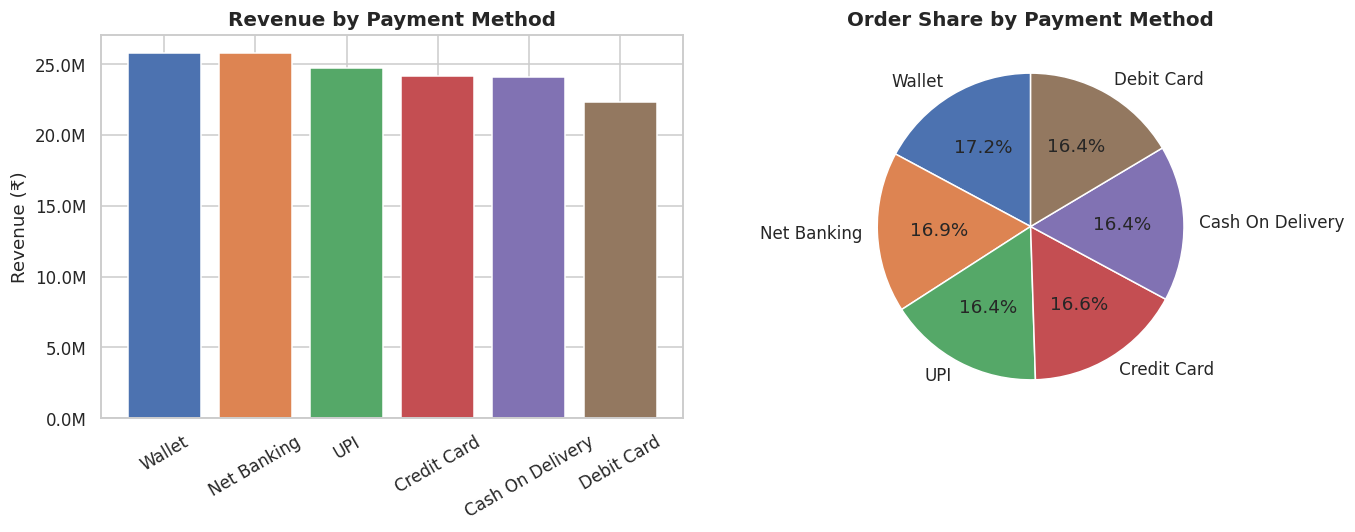

,Revenue,Orders
Payment_Method,,
Wallet,25790064.54,2080
Net Banking,25762180.37,2053
UPI,24724885.75,1987
Credit Card,24159269.49,2016
Cash On Delivery,24091931.51,1989
Debit Card,22305776.02,1993


In [8]:
payment_dist = df.groupby('Payment_Method')['Sales'].agg(['sum', 'count']).rename(
    columns={'sum': 'Revenue', 'count': 'Orders'}
).sort_values('Revenue', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(payment_dist.index, payment_dist['Revenue'], color=sns.color_palette('deep', len(payment_dist)))
axes[0].set_title('Revenue by Payment Method')
axes[0].set_ylabel('Revenue (₹)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
axes[0].tick_params(axis='x', rotation=30)

axes[1].pie(payment_dist['Orders'], labels=payment_dist.index, autopct='%1.1f%%',
            colors=sns.color_palette('deep', len(payment_dist)), startangle=90)
axes[1].set_title('Order Share by Payment Method')

plt.tight_layout()
plt.savefig(f'{IMG_DIR}/06_payment_method_analysis.png', bbox_inches='tight')
plt.show()

payment_dist


## 8. Revenue vs Profit Analysis (by Category)

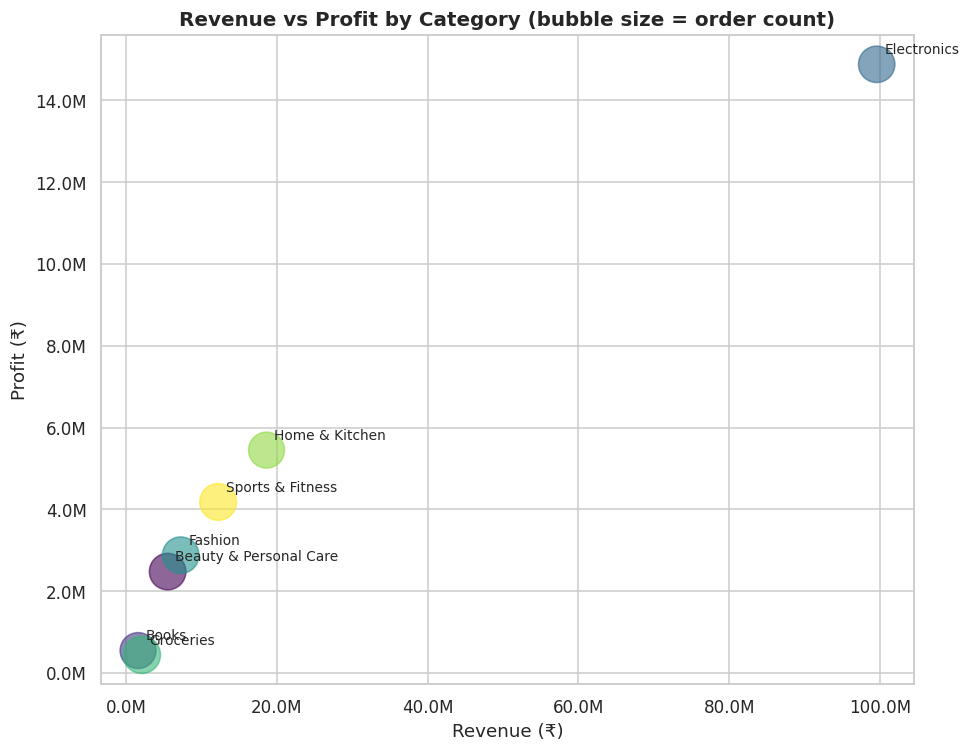

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
sizes = (df.groupby('Product_Category')['Order_ID'].nunique())
cat_summary = df.groupby('Product_Category').agg(Revenue=('Sales','sum'), Profit=('Profit','sum')).reset_index()
cat_summary['Orders'] = cat_summary['Product_Category'].map(sizes)

scatter = ax.scatter(cat_summary['Revenue'], cat_summary['Profit'],
                      s=cat_summary['Orders']/3, alpha=0.6,
                      c=range(len(cat_summary)), cmap='viridis')

for _, row in cat_summary.iterrows():
    ax.annotate(row['Product_Category'], (row['Revenue'], row['Profit']),
                fontsize=9, ha='left', va='bottom', xytext=(5, 5), textcoords='offset points')

ax.set_title('Revenue vs Profit by Category (bubble size = order count)')
ax.set_xlabel('Revenue (₹)')
ax.set_ylabel('Profit (₹)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/07_revenue_vs_profit.png', bbox_inches='tight')
plt.show()


## 9. Customer Segmentation Chart (preview)

Full RFM-based segmentation is built in `04_rfm_cohort_analysis.ipynb`. Here
we preview a simple value-tier segmentation by Customer Lifetime Value
quartile, useful as a quick visual.


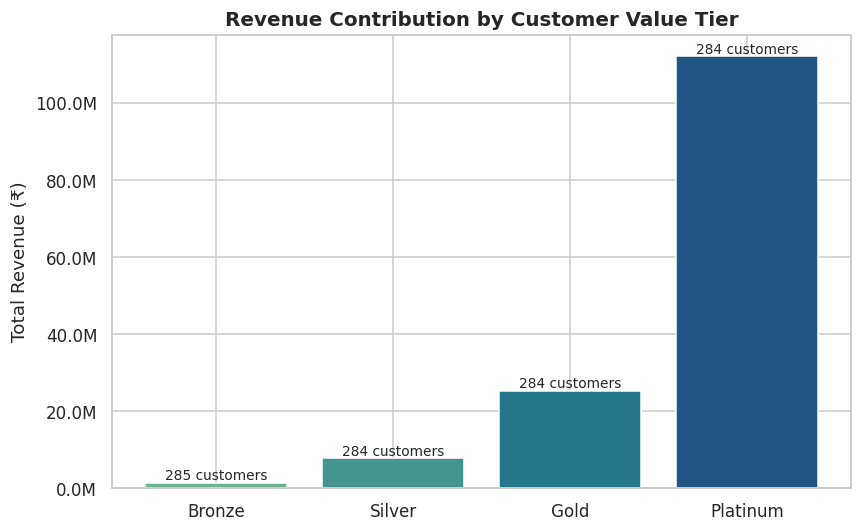

,CLV_Tier,Customers,Total_Revenue
0,Bronze,285,1.456012e+06
1,Silver,284,7.852601e+06
2,Gold,284,2.540292e+07
3,Platinum,284,1.121226e+08


In [10]:
customers['CLV_Tier'] = pd.qcut(customers['Customer_Lifetime_Value'], 4,
                                 labels=['Bronze', 'Silver', 'Gold', 'Platinum'])

tier_summary = customers.groupby('CLV_Tier').agg(
    Customers=('Customer_ID', 'count'),
    Total_Revenue=('Customer_Lifetime_Value', 'sum')
).reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(tier_summary['CLV_Tier'], tier_summary['Total_Revenue'],
              color=sns.color_palette('crest', 4))
ax.set_title('Revenue Contribution by Customer Value Tier')
ax.set_ylabel('Total Revenue (₹)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
for bar, cust in zip(bars, tier_summary['Customers']):
    h = bar.get_height()
    ax.annotate(f'{cust} customers', (bar.get_x() + bar.get_width()/2, h),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/08_customer_segmentation_tiers.png', bbox_inches='tight')
plt.show()

tier_summary


---
**Next notebook:** `04_rfm_cohort_analysis.ipynb` — full RFM segmentation,
cohort retention analysis, and advanced KPIs (Revenue Growth %, Retention
Rate, Repeat Purchase Rate, Average Basket Size).
